In [7]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready')


Model is ready


In [8]:
# Tools definition
from langchain_community.tools import tool

@tool
def get_weather(city: str) -> str:
    """Get weather for a city"""
    return f"The weather in the city {city} is Sunny"

@tool
def get_stock_price(stock: str) -> str:
    """Returns the stock price for a given stock"""
    return f"The stock price of {stock} is 25.50"

ALL_TOOLS = [get_weather, get_stock_price]
print('Tools are ready')

Tools are ready


In [9]:
# STEP 1: Define your state
from typing import TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph.message import Annotated, add_messages

class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

print('State is defined')

State is defined


In [10]:
# STEP 2: Define your nodes

model_with_tools = model.bind_tools(ALL_TOOLS)

def assistant_node(state: AgentState) -> dict:
    """One graph noce: call the LLM using current messages"""
    response = model_with_tools.invoke(state['messages'])
    return {"messages": [response]}

def route_after_assistant_node(state: AgentState) -> str:
    """Route to tools only when model produces tool calls"""
    last_message = state['messages'][-1]
    if last_message.tool_calls:
        return "tools_key"
    return "end_key"
print('Nodes are defined')

Nodes are defined


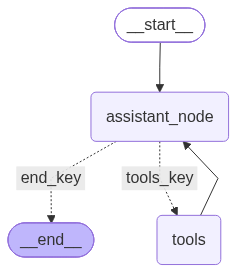

In [13]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode

graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant_node", assistant_node)
graph_builder.add_node("tools", ToolNode(ALL_TOOLS))

# Add edges to nodes
graph_builder.add_edge(START, "assistant_node")
graph_builder.add_conditional_edges(
    "assistant_node",
    route_after_assistant_node,
    {
        "tools_key": "tools",
        "end_key": END
    }
)
graph_builder.add_edge("tools", "assistant_node")
graph = graph_builder.compile()
graph

In [14]:
response = graph.invoke({"messages": [{"role": "user", "content": "How is the weather in Pune today?"}]})
response

{'messages': [HumanMessage(content='How is the weather in Pune today?', additional_kwargs={}, response_metadata={}, id='c7a0bf5d-29c5-48f3-adab-d7b1e41d6406'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-23T05:27:45.788091567Z', 'done': True, 'done_reason': 'stop', 'total_duration': 309952956, 'load_duration': None, 'prompt_eval_count': 154, 'prompt_eval_duration': None, 'eval_count': 53, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a1673a-b911-7aa2-9aff-852d54d4cebf-0', tool_calls=[{'name': 'get_weather', 'args': {'city': 'Pune'}, 'id': '6d9a5152-bded-4857-8e0c-67dd290ad204', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 154, 'output_tokens': 53, 'total_tokens': 207}),
  ToolMessage(content='The weather in the city Pune is Sunny', name='get_weather', id='47dc19d7-c7e4-4439-b7a8-d0d56c2f2d5d', tool_call_id='6d9a5152-bd

In [15]:
response = graph.invoke({"messages": [{"role": "user", "content": "Who is the president of India?"}]})
response

{'messages': [HumanMessage(content='Who is the president of India?', additional_kwargs={}, response_metadata={}, id='8733e24c-b1ad-4e26-a12c-255beb253210'),
  AIMessage(content='As of\u202fOctober\u202f2026, the President of India is **Droupadi\u202fMurmu**. She was elected to a five‑year term in July\u202f2022 and is serving as the nation’s head of state until the next presidential election, scheduled for 2027.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-23T05:28:46.959847008Z', 'done': True, 'done_reason': 'stop', 'total_duration': 617783820, 'load_duration': None, 'prompt_eval_count': 153, 'prompt_eval_duration': None, 'eval_count': 175, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a1673b-a737-7fb3-b542-1532579410dc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 153, 'output_tokens': 175, 'total_tokens': 328})]}